# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [54]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [55]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [56]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [57]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [58]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [59]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [60]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [61]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [62]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos
### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [63]:
# cantidad de nulos para users
print(users.isna().sum().sort_values(ascending=False)) # Cantidad de valores nulos
print()
print(users.isna().mean().sort_values(ascending=False)) # Proporción de valores nulos

churn_date    3534
city           469
user_id          0
first_name       0
last_name        0
age              0
reg_date         0
plan             0
dtype: int64

churn_date    0.88350
city          0.11725
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
reg_date      0.00000
plan          0.00000
dtype: float64


In [64]:
# cantidad de nulos para usage
print(usage.isna().sum().sort_values(ascending=False))
print()
print(usage.isna().mean().sort_values(ascending=False))

duration    22076
length      17896
date           50
id              0
user_id         0
type            0
dtype: int64

duration    0.55190
length      0.44740
date        0.00125
id          0.00000
user_id     0.00000
type        0.00000
dtype: float64



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?


**Diagnóstico de datos**

**DF_users**
- La columna **`churn_date`** presenta un 88.35% de valores nulos, lo que sugiere que el 11.65% de los usuarios ha cancelado su plan telefónico. Se recomienda conservar los nulos, ya que podrían representar usuarios activos.
- La columna **`city`** presenta un 11.72% de valores faltantes, lo que puede afectar el análisis demográfico. Se recomienda conservar los registros y clasificar los valores faltantes como "Desconocida", evitando asignar una ciudad sin evidencia.
- Es necesario convertir las columnas **`reg_date`** y **`churn_date`** al tipo de dato `datetime` para facilitar su análisis.

**DF_usage**
- Las columnas **`duration`** (55.19%) y **`length`** (44.74%) presentan valores nulos. Sin embargo, es necesario analizar su relación con la columna **`type`** para determinar si representan datos faltantes o si corresponden al tipo de actividad registrada (`call` o `text`). Por el momento, no se recomienda imputarlos.
- La columna **`date`** presenta un 0.12% de valores faltantes. Dada su baja proporción, se recomienda excluir estos registros de los análisis que requieran información temporal.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [65]:
# explorar columnas numéricas de users
cols_num_users = users[['user_id', 'age']]
print("user_id:", users['user_id'].nunique())
print()
print(cols_num_users.describe())
print()
print('sentinel_age:', users['age'].isin([-999]).sum())

user_id: 4000

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000

sentinel_age: 55


- La columna `user_id` contiene 4,000 registros únicos y no nulos.
- La columna `age` presenta 55 valores *sentinel* (`-999`), equivalentes al 1.38% de los registros, los cuales distorsionan las estadísticas descriptivas. Dada su baja proporción y la cercanía entre la media y la mediana de las edades válidas, se recomienda imputarlos utilizando la media calculada sin considerar los valores sentinel.

In [66]:
# explorar columnas numéricas de usage
cols_num_usage = usage[['id', 'user_id', 'duration', 'length']]
print(cols_num_usage.nunique())
print()
print(cols_num_usage.describe())

id          40000
user_id      3999
duration     2090
length        123
dtype: int64

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id` contienen 40,000 registros no nulos. La primera presenta 40,000 valores únicos, lo que confirma que no hay identificadores de actividad duplicados. La segunda contiene 3,999 usuarios únicos, lo que indica que existen múltiples registros de actividad por usuario.

- Las columnas `duration` (17,924 registros no nulos) y `length` (22,104 registros no nulos) presentan valores faltantes que podrían estar relacionados con el tipo de actividad (`call` o `text`). Se recomienda verificar esta relación antes de realizar imputaciones.

- Las estadísticas descriptivas muestran posibles valores atípicos: `duration` presenta una mediana de 3.5 y un máximo de 120, mientras que `length` presenta una mediana de 50 y un máximo de 1,490. Se recomienda investigar estos valores mediante visualizaciones y métodos estadísticos.

In [67]:
# explorar columnas categóricas de users
cols_cat_users = users[['city', 'plan']]
print(cols_cat_users.describe())
print()
print(cols_cat_users.value_counts())
print()
print('Nulos_city:', users['city'].isna().sum())
print()
print('Sentinels_city:', (users['city'] == '?').sum())

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595

city      plan   
Bogotá    Basico     522
CDMX      Basico     474
Medellín  Basico     398
GDL       Basico     298
Bogotá    Premium    286
MTY       Basico     275
Cali      Basico     262
CDMX      Premium    256
Medellín  Premium    218
Cali      Premium    162
GDL       Premium    152
MTY       Premium    132
?         Basico      65
          Premium     31
dtype: int64

Nulos_city: 469

Sentinels_city: 96


- La columna `city` presenta 469 valores nulos (11.73%) y 96 valores *sentinel* (`?`), equivalentes al 2.40% de los registros. En conjunto, representan un 14.13% de usuarios sin una ciudad identificable. Se recomienda reemplazar los valores *sentinel* por nulos y clasificar los registros faltantes como "NA" para el análisis demográfico.

- La columna `plan` contiene 4,000 registros no nulos y dos categorías: Básico (2,595 usuarios) y Premium (1,405 usuarios). No presenta valores faltantes y sus categorías coinciden con los planes disponibles.confirma los valores faltantes, presenta 65 valores *sentinel* (`?`), equivalentes al 1.84% de los registros, y 31 datos vacíos, equivalentes a 0.87%, confirmado con [cols_cat_users.value_counts(normalize=True)].

In [68]:
# explorar columna categórica de usage
print(usage['type'].describe())
print()
print(usage['type'].value_counts())


count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

text    22092
call    17908
Name: type, dtype: int64


- La columna `type` contiene 40,000 registros completos, sin valores nulos, distribuidos en dos categorías: **`text`** (22,092 registros, 55.23%) y **`call`** (17,908 registros, 44.77%). Esta distribución sugiere que los valores `NaN` en las columnas **`duration`** y **`length`** se deben principalmente al tipo de actividad registrada. Por lo tanto, estos valores nulos podrían ser esperados y no requerir imputación.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**

- Se identificaron valores *sentinel* en las columnas **`age`** (`-999`) y **`city`** (`?`). Se recomienda reemplazarlos por valores nulos para evitar distorsiones en el análisis.
- Para **`age`**, se recomienda imputar los valores inválidos utilizando la mediana de las edades válidas. Para **`city`**, se conservarán como nulos y podrán clasificarse como "NA" durante la segmentación.
- Adicionalmente, se recomienda validar las fechas y revisar posibles inconsistencias en **`duration`** y **`length`** antes de realizar la limpieza.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [69]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
print(users['reg_date'].describe())
print()
print('Fechas posteriores a 2024:', (users['reg_date'] > '2024-12-31').sum())

count                    4000
unique                   3961
top       2026-05-10 00:00:00
freq                       40
first     2022-01-01 00:00:00
last      2026-05-10 00:00:00
Name: reg_date, dtype: object

Fechas posteriores a 2024: 40


In [70]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
print(usage['date'].describe())
print()
print('Fechas posteriores a 2024:', (usage['date'] > '2024-12-31').sum())

count                             39950
unique                            39950
top       2024-06-16 13:26:59.770494262
freq                                  1
first               2024-01-01 00:00:00
last                2024-06-30 00:00:00
Name: date, dtype: object

Fechas posteriores a 2024: 0


In [71]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, se identificaron 40 registros correspondientes al año 2026, los cuales se encuentran fuera del período de análisis establecido, que comprende únicamente datos hasta 2024. Se recomienda excluir estos registros del análisis.

In [72]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

En `date`, se identificaron únicamente registros del año 2024 de acuerdo al período de análisis.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- La columna `reg_date` de **users** y `date` de **usage** no presentan  años imposibles, pero si se identificaron registros del año 2026 en la columna `reg_date`, el cual no ha transcurrido al momento de guardar los datos.
- Se recomienda confirmar el error con el equipo de datos y por el momento excluir estos registros del análisis. 

---
## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [73]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [74]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", "NA")

# Verificar cambios
users['city'].value_counts()

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
NA           96
Name: city, dtype: int64

In [75]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'] > '2024-12-31', 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].isna().sum()

40

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [76]:
# Verificación MAR en usage (Missing At Random) para duration
print('Total de llamadas:', (usage['type'] == 'call').sum())
print(usage.loc[usage['type'] == 'call', 'duration'].isna().value_counts())
print(usage.loc[usage['type'] == 'call', 'length'].isna().value_counts())

Total de llamadas: 17908
False    17908
Name: duration, dtype: int64
True     17896
False       12
Name: length, dtype: int64


In [77]:
# Verificación MAR en usage (Missing At Random) para length
print('Total de textos:', (usage['type'] == 'text').sum())
print(usage.loc[usage['type'] == 'text', 'length'].isna().value_counts())
print(usage.loc[usage['type'] == 'text', 'duration'].isna().value_counts())

Total de textos: 22092
False    22092
Name: length, dtype: int64
True     22076
False       16
Name: duration, dtype: int64


Los valores nulos en `duration` y `length` son **MNAR** (*Missing Not At Random*), que dependen de la columa `type` que muestra el tipo de actividad registrada para relacionarse con `duration`para llamdas, y `length`, sin embargo se identificaron 12 llamadas con datos en `lenght`y 16 textos con datos en `duration`, los cuales se deben ignorar.

---
## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [78]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Crear una columna exclusiva para minutos de llamadas
usage['minutos_llamada'] = 0.0
usage.loc[usage['type'] == 'call', 'minutos_llamada'] = usage.loc[usage['type'] == 'call', 'duration']

# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text', 'is_call', 'minutos_llamada']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [79]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'minutos_llamada': 'cant_minutos_llamada'
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [80]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 Resumen estadístico por usuario durante el 2024 
🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [94]:
# Resumen estadístico de las columnas numéricas
col_num_user_profile = user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']]
col_num_user_profile.describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,22.836934
std,17.690408,2.358416,2.144238,16.590213
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.095000
50%,47.000000,5.000000,4.000000,19.740000
75%,63.000000,7.000000,6.000000,31.185000
max,79.000000,17.000000,15.000000,155.690000


In [93]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

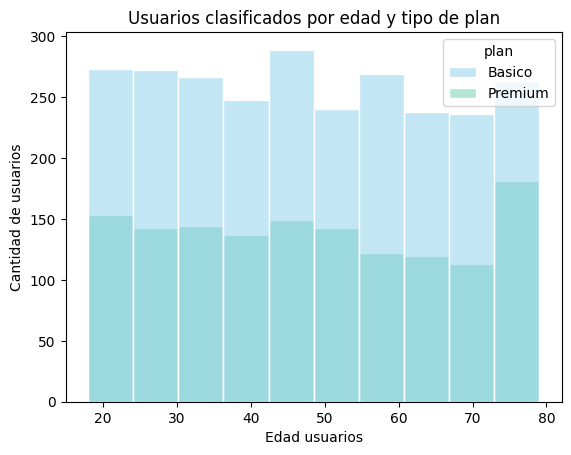

In [105]:
# Histograma para visualizar la edad (age)
sns.histplot(
    data=user_profile,
    x='age',
    bins=10,
    hue='plan',
    palette={'Basico': 'skyblue', 'Premium': 'mediumaquamarine'},
    edgecolor='white'
)

plt.xlabel('Edad usuarios')
plt.ylabel('Cantidad de usuarios')
plt.title('Usuarios clasificados por edad y tipo de plan')
plt.show()


💡Insights: 
- Las distribución en las edades de los usuarios es equilibrada, al igual que sus preferencias por plan Basico o Premium sin embargo se observa un incremento en la cantidad de usuarios del plan Premium en el rango de mayor edad (aproximadamente 74 a 79 años), lo que podría indicar un comportamiento diferenciado que convendría analizar con mayor detalle.

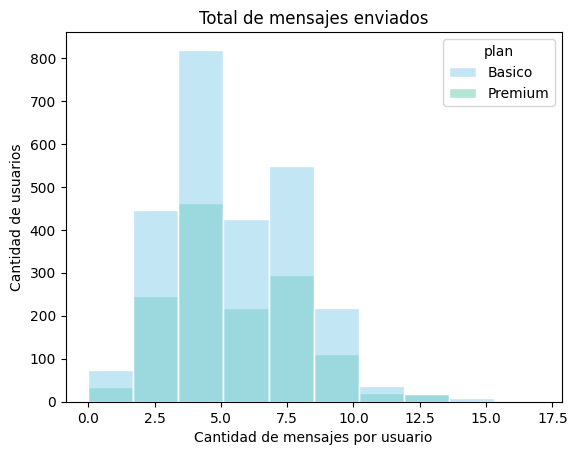

In [112]:
# Histograma para visualizar la cant_mensajes

sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    bins=10,
    hue='plan',
    palette={'Basico': 'skyblue', 'Premium': 'mediumaquamarine'},
    edgecolor='white'
)
plt.xlabel('Cantidad de mensajes por usuario')
plt.ylabel('Cantidad de usuarios')
plt.title('Total de mensajes enviados')
plt.show()



💡Insights: 
- La mayor concentración de usuarios registra entre 2 y 9 mensajes, con una frecuencia máxima alrededor de 4 a 5 mensajes por usuario.
- El intervalo cercano a 4–5 mensajes presenta la frecuencia más alta.
- Hay pocos usuarios que envían más de 10 mensajes, lo que genera una *right skew distribution*.
- El plan Básico presenta más usuarios en prácticamente todos los intervalos, aunque se ve influenciado por la mayor cantidad de clientes con plan Básico contratado.

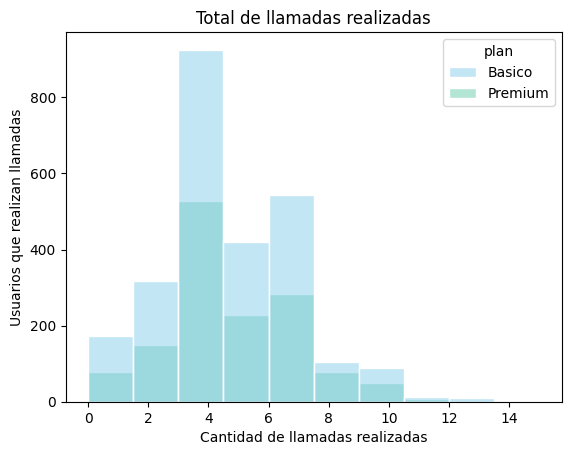

In [113]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    bins=10,
    hue='plan',
    palette={'Basico': 'skyblue', 'Premium': 'mediumaquamarine'},
    edgecolor='white'
)
plt.xlabel('Cantidad de llamadas realizadas')
plt.ylabel('Usuarios que realizan llamadas')
plt.title('Total de llamadas realizadas')
plt.show()



💡Insights: 
- La mayor concentración de usuarios realiza entre 3 y 7 llamadas.
- La distribución presenta una *right skew distribution*, con una disminución en la frecuencia a partir de las 8 llamadas. Se identifican pocos usuarios que realizan más de 10 llamadas, lo que podría representar un segmento de mayor consumo.
- Ambos planes presentan patrones de uso similares, con una concentración de llamadas en los mismos intervalos. 

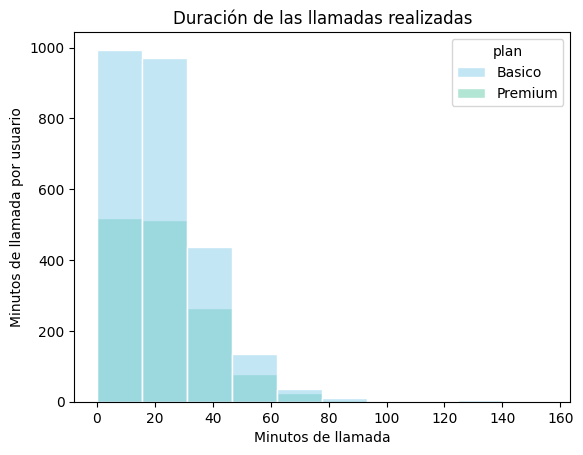

In [117]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    bins=10,
    hue='plan',
    palette={'Basico': 'skyblue', 'Premium': 'mediumaquamarine'},
    edgecolor='white'
)
plt.xlabel('Minutos de llamada')
plt.ylabel('Minutos de llamada por usuario')
plt.title('Duración de las llamadas realizadas')
plt.show()


💡Insights: 
- La mayoría de los usuarios acumula entre 0 y 40 minutos de llamadas, con una mayor concentración en los primeros 20 minutos.
- La distribución presenta uuna *right skew distribution*, con pocos usuarios que superan los 60 minutos, lo que podría indicar comportamientos de consumo atípicos.
- Ambos planes presentan patrones de consumo similares, aunque el plan Básico concentra una mayor cantidad de usuarios.
- El bajo consumo general de minutos podría representar una oportunidad para evaluar si los minutos incluidos en los planes se ajustan a las necesidades reales de los clientes.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

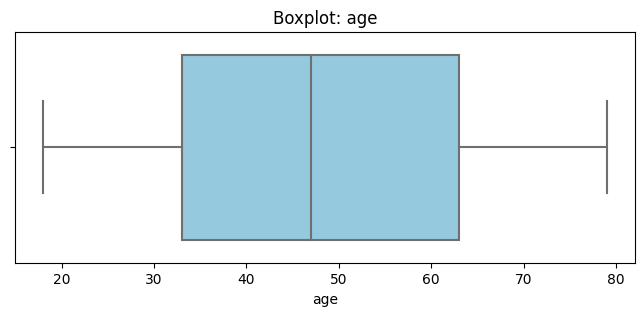

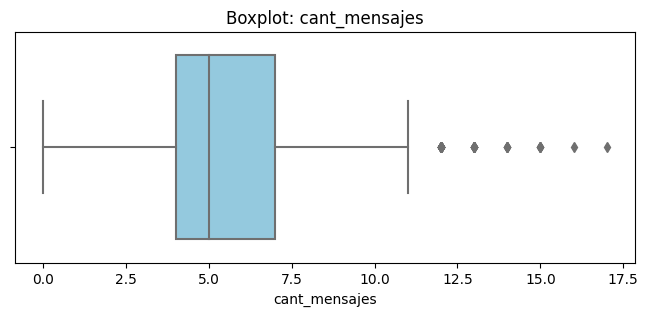

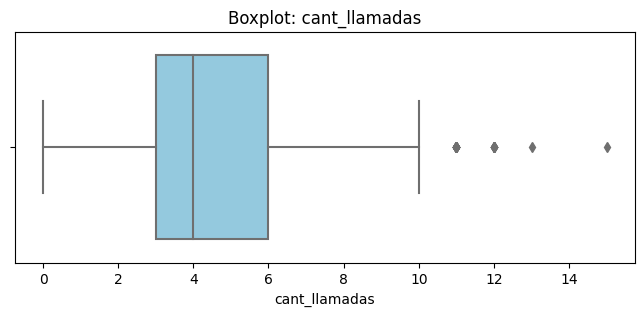

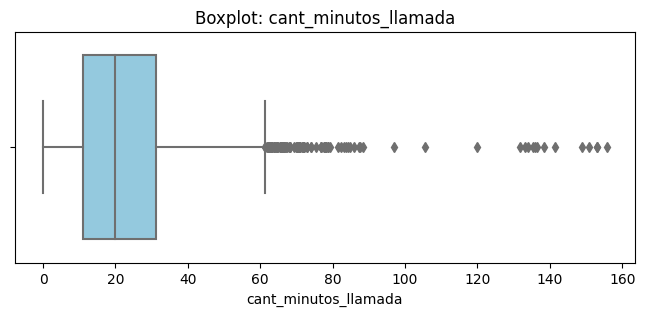

In [121]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')


💡Insights: 
- Age: No presenta outliers. Las edades se encuentran dentro de un rango esperado, entre 18 y 79 años.
- cant_mensajes: Presenta algunos valores atípicos superiores, correspondientes a usuarios que enviaron 12 o más mensajes.
- cant_llamadas: Presenta algunos valores atípicos superiores, correspondientes a usuarios que realizaron más de 10 llamadas.
- cant_minutos_llamada: Presenta bastantes valores atípicos, correspondientes a usuarios que acumularon más de 61.32 minutos de llamadas.

In [135]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_limites:
    print(col)
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    Limite_inferior = Q1 - 1.5 * IQR
    Limite_superior = Q3 + 1.5 * IQR
    outliers = user_profile.loc[
    (user_profile[col] < Limite_inferior) |
    (user_profile[col] > Limite_superior)]
    print('Límite inferior:', Limite_inferior)
    print('Límite superior:', Limite_superior)
    print('Cantidad de outliers:', len(outliers))
    print()


cant_mensajes
Límite inferior: -0.5
Límite superior: 11.5
Cantidad de outliers: 46

cant_llamadas
Límite inferior: -1.5
Límite superior: 10.5
Cantidad de outliers: 30

cant_minutos_llamada
Límite inferior: -19.04
Límite superior: 61.31999999999999
Cantidad de outliers: 96



In [133]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,22.836934
std,2.358416,2.144238,16.590213
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.095000
50%,5.000000,4.000000,19.740000
75%,7.000000,6.000000,31.185000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: Se identificaron 46 outliers (1.15%) que superan los 11.5 mensajes. Se recomienda conservarlos, ya que podrían representar usuarios con mayor actividad de mensajería.
- cant_llamadas: Se identificaron 30 outliers (0.75%) que superan las 10.5 llamadas. Se recomienda conservarlos, pues podrían corresponder a usuarios con un patrón de consumo elevado.
- cant_minutos_llamada: Se identificaron 96 outliers (2.40%) que superan los 61.32 minutos, alcanzando un máximo de 155.69 minutos. Se recomienda conservarlos, previa validación, ya que podrían representar usuarios con necesidades de consumo diferenciadas.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [136]:
# Crear columna grupo_uso
def segmentar(row):
    llamada = row['cant_llamadas']
    mensaje = row['cant_mensajes']

    if pd.isna(llamada) or pd.isna(mensaje):
        return "Error en datos"

    if llamada < 5 and mensaje < 5:
        return "Bajo uso"
    elif llamada < 10 and mensaje < 10:
        return "Uso medio"
    else:
        return "Alto uso"

user_profile['grupo_uso'] = user_profile.apply(segmentar, axis=1)


In [151]:
# verificar cambios
print(user_profile['grupo_uso'].value_counts(normalize=True))
print()
print(user_profile['grupo_uso'].value_counts())
user_profile.head()

Uso medio         0.73575
Bajo uso          0.19450
Alto uso          0.06950
Error en datos    0.00025
Name: grupo_uso, dtype: float64

Uso medio         2943
Bajo uso           778
Alto uso           278
Error en datos       1
Name: grupo_uso, dtype: int64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [138]:
# Crear columna grupo_edad
def segmentar_edad(row):
    edad = row['age']

    if pd.isna(edad):
        return "Error en datos"

    if edad < 30:
        return "Joven"
    elif edad < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

user_profile['grupo_edad'] = user_profile.apply(segmentar_edad, axis=1)

In [150]:
# verificar cambios
print(user_profile['grupo_edad'].value_counts(normalize=True))
print()
print(user_profile['grupo_edad'].value_counts())
user_profile.head()

Adulto          0.5045
Adulto Mayor    0.3055
Joven           0.1900
Name: grupo_edad, dtype: float64

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

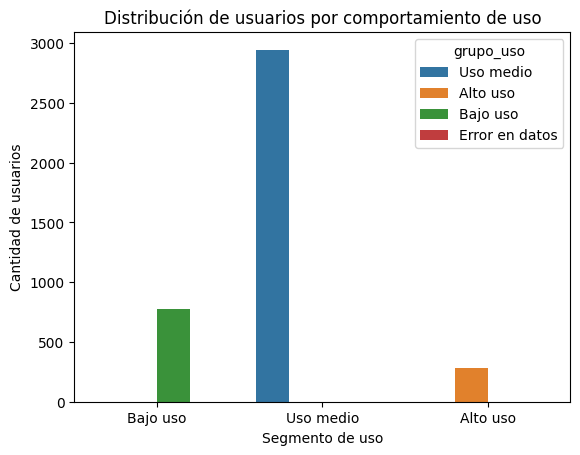

In [143]:
# Visualización de los segmentos por uso
sns.countplot(
    data=user_profile,
    x='grupo_uso',
    hue='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso']
)

plt.xlabel('Segmento de uso')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios por comportamiento de uso')
plt.show()



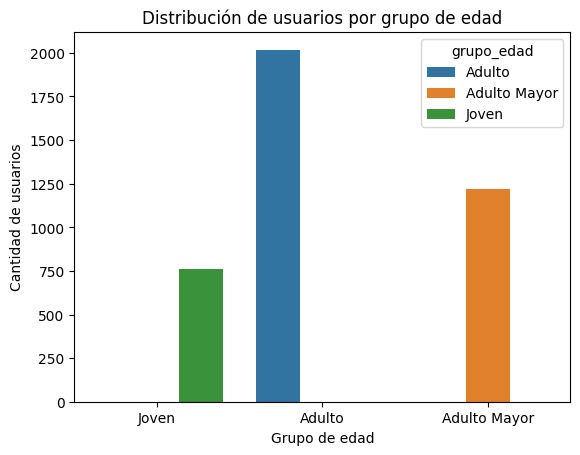

In [144]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    hue='grupo_edad',
    order=['Joven', 'Adulto', 'Adulto Mayor']
)

plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios por grupo de edad')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Valores faltantes: Se identificaron 3,534 valores nulos (88.35%) en churn_date, que podrían corresponder a usuarios activos, y 565 registros (14.13%) sin una ciudad identificable en city, considerando valores nulos y sentinels.
- Valores inválidos: Se detectaron 55 edades con el valor sentinel -999 (1.38%), que fueron reemplazadas utilizando la mediana, y 40 fechas de registro correspondientes a 2026 (1%), fuera del período de análisis, que fueron marcadas como nulas.
- Inconsistencias en el uso: Se identificaron 28 registros con información en columnas que no corresponden a su tipo de actividad, además de 50 registros sin fecha. Los nulos de duration y length asociados al tipo de actividad se conservaron por ser esperados.

🔍 **Segmentos por Edad**
- Adultos (30–59 años): Representan el segmento más numeroso, con 2,018 usuarios (50.45%).
- Adultos mayores (60 años o más): Constituyen el 30.55% de los clientes, con 1,222 usuarios.
- Jóvenes (menores de 30 años): Representan el 19% de la base, con 760 usuarios.
- Los tres grupos presentan patrones de consumo similares, con promedios cercanos a 5.5 mensajes, 4.5 llamadas y 23 minutos de llamadas por usuario. Por lo tanto, la edad no parece ser un factor determinante en el nivel de consumo.

📊 **Segmentos por Nivel de Uso**
- Uso medio: Es el segmento predominante, con 2,943 usuarios (73.58%), lo que indica que la mayoría mantiene un consumo moderado de llamadas y mensajes.
- Bajo uso: Representa el 19.45% de los clientes (778 usuarios), quienes podrían beneficiarse de planes con menores capacidades y precios más accesibles.
- Alto uso: Comprende 278 usuarios (6.95%), que presentan una mayor actividad y podrían representar oportunidades comerciales para planes especializados.
- Comparación de planes: El plan Básico concentra el 64.88% de los clientes y Premium el 35.12%. Sin embargo, ambos presentan promedios de consumo muy similares, lo que sugiere que la contratación de un plan Premium no necesariamente está relacionada con un mayor uso de llamadas o mensajes.
- Valores atípicos: Se identificaron 46 usuarios con consumo superior a 11.5 mensajes, 30 con más de 10.5 llamadas y 96 con más de 61.32 minutos acumulados. Se recomienda conservar estos registros, previa validación, ya que podrían representar necesidades de consumo diferenciadas.

➡️ Esto sugiere que el comportamiento de consumo es relativamente homogéneo entre edades y tipos de plan. La mayor oportunidad de segmentación parece encontrarse en los niveles y características del uso, especialmente en clientes con consumos elevados. Asimismo, los usuarios Premium podrían representar un segmento de mayor ingreso por suscripción, aunque sería necesario analizar su rentabilidad y necesidades reales para confirmar su valor comercial.

💡 **Recomendaciones**
- Optimizar los planes actuales: Evaluar si los beneficios de los planes Básico y Premium corresponden al consumo real de los usuarios, ya que ambos segmentos presentan patrones de llamadas y mensajes similares.
- Diseñar opciones para usuarios de bajo consumo: Considerar planes más económicos, con menores cantidades incluidas de llamadas y mensajes, para atender a los clientes que utilizan poco estos servicios.
- Desarrollar ofertas para usuarios de alto consumo: Identificar clientes con necesidades superiores al promedio y evaluar paquetes adicionales de llamadas o mensajes, así como opciones con mayores beneficios.
- Diferenciar el consumo por duración: Considerar los minutos acumulados además de la cantidad de llamadas, ya que algunos usuarios pueden realizar pocas llamadas, pero de larga duración.
- Profundizar el análisis comercial: Antes de modificar los planes, comparar el consumo mensual con los beneficios incluidos, incorporar el uso de datos móviles (GB) y evaluar ingresos, cancelaciones y satisfacción para determinar qué segmentos generan mayor valor para ConnectaTel.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`